# Exercise 4: E-Commerce Text & Quantitative Analytics
Dataset: *Flipkart Product Customer Reviews* (Kaggle, `niraliivaghani/flipkart-product-customer-reviews-dataset`). Download the CSV (`Dataset-SA.csv`) from Kaggle and place it beside this notebook, or use the `kagglehub` cell.

In [2]:
import os, glob
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Load: local file first, otherwise download via kagglehub
csv = 'Dataset-SA.csv'
if not os.path.exists(csv):
    import kagglehub
    path = kagglehub.dataset_download('niraliivaghani/flipkart-product-customer-reviews-dataset')
    csv = glob.glob(os.path.join(path, '*.csv'))[0]
df = pd.read_csv(csv)
print(df.shape); print(df.columns.tolist()); df.head()

(205052, 6)
['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [3]:
# Step 1: Clean rating and price fields
# Price may contain commas / currency symbols; rating may contain stray non-numeric text
df['product_price'] = (df['product_price'].astype(str)
                       .str.replace(r'[^0-9.]', '', regex=True))
df['product_price'] = pd.to_numeric(df['product_price'], errors='coerce')
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')
print('Rows before dropna:', len(df))
df = df.dropna(subset=['Rate', 'product_price'])
print('Rows after dropna:', len(df))

Rows before dropna: 205052
Rows after dropna: 205049


In [4]:
# Step 2: Mean rating and mean price per product -> DataFrame named `items`
items = (df.groupby('product_name')[['Rate', 'product_price']]
           .mean().round(2).reset_index()
           .rename(columns={'Rate':'mean_rating', 'product_price':'mean_price'}))
items

,product_name,mean_rating,mean_price
0,1170BLBR Unique New Day Date Analog Watch F...,3.99,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.41,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.89,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.67,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.75,199.0
...,...,...,...
953,tHemiStO Beginners 8 in 1 Soldering iron Kit 2...,4.24,232.0
954,the indian casa Cricket Net 10x20 Feet Nylon C...,3.92,340.0
955,thos 5 Layer Simple BookshelfMultipurpose Rack...,3.38,785.0
956,thos 5 Layer Simple BookshelfMultipurpose Rack...,3.41,799.0


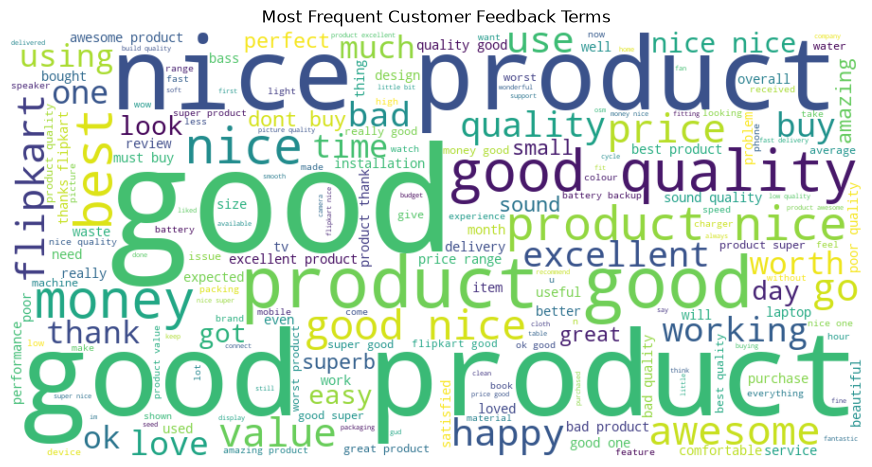

In [5]:
# Step 3: Word cloud from the Summary column
text = ' '.join(df['Summary'].dropna().astype(str))
wc = WordCloud(width=900, height=450, background_color='white',
               stopwords=set(__import__('wordcloud').STOPWORDS)).generate(text)
plt.figure(figsize=(11,6))
plt.imshow(wc, interpolation='bilinear'); plt.axis('off')
plt.title('Most Frequent Customer Feedback Terms')
plt.show()